# 4. Model Validation Report

**Project:** Credit Risk Scoring and Model Validation
**Objective:** Assess the developed models with quantitative and qualitative approaches and report the validation findings within a model risk management framework.

### Validation Framework
This validation report assesses the models under the following headings:
1. **Discrimination:** ROC-AUC, KS Statistic, Gini
2. **Calibration:** Predicted vs observed default rates
3. **Decile Analysis:** Effectiveness of the risk ranking
4. **Segment Performance:** Model consistency across subgroups
5. **Stability:** Train-test comparison, PSI-style drift analysis
6. **Model Interpretation:** Explainability with SHAP values
7. **Champion vs Challenger:** Assessment of significant differences between the models

---

## 4.1 Libraries and Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report, brier_score_loss)
from sklearn.calibration import calibration_curve
from scipy import stats
import joblib
import shap

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

print("Libraries loaded.")

Libraries loaded.


In [2]:
# Load the data and models
df_full = pd.read_csv('../data/credit_features.csv', index_col='ID')
predictions = pd.read_csv('../data/predictions.csv', index_col='ID')
train_preds = pd.read_csv('../data/train_predictions.csv', index_col='ID')
feature_list = pd.read_csv('../data/feature_list.csv')['feature'].tolist()
meta = pd.read_csv('../data/model_metadata.csv', index_col=0, header=0)

lr_model = joblib.load('../models/logistic_regression.pkl')
xgb_model = joblib.load('../models/xgboost.pkl')
scaler = joblib.load('../models/scaler.pkl')

# Also prepare the test data
test_features = df_full.loc[predictions.index, feature_list]
test_features_scaled = pd.DataFrame(
    scaler.transform(test_features),
    columns=feature_list,
    index=test_features.index
)

y_test = predictions['y_true']
y_prob_lr = predictions['y_prob_lr']
y_prob_xgb = predictions['y_prob_xgb']

print(f"Test set: {len(y_test):,} observations")
print(f"Test default rate: {y_test.mean():.4f}")
print(f"Number of features: {len(feature_list)}")

Test set: 6,000 observations
Test default rate: 0.2212
Number of features: 39


## 4.2 Discrimination

Discrimination measures how well the model can separate default and non-default customers.

### Metrics:
- **ROC-AUC:** Between 0.5 (random) and 1.0 (perfect)
- **Gini Coefficient:** 2 × AUC - 1
- **KS Statistic:** Maximum of the difference between the cumulative distributions

In [3]:
# ROC-AUC and Gini
auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_xgb = roc_auc_score(y_test, y_prob_xgb)
gini_lr = 2 * auc_lr - 1
gini_xgb = 2 * auc_xgb - 1

print("=== Discrimination Metrics ===")
print(f"{'Metric':<20} {'Logistic Reg':>15} {'XGBoost':>15}")
print(f"{'-'*50}")
print(f"{'ROC-AUC':<20} {auc_lr:>15.4f} {auc_xgb:>15.4f}")
print(f"{'Gini':<20} {gini_lr:>15.4f} {gini_xgb:>15.4f}")

=== Discrimination Metrics ===
Metric                  Logistic Reg         XGBoost
--------------------------------------------------
ROC-AUC                       0.7471          0.7830
Gini                          0.4943          0.5659


KS Statistic                  0.3887          0.4223
KS Threshold                  0.5733          0.5204


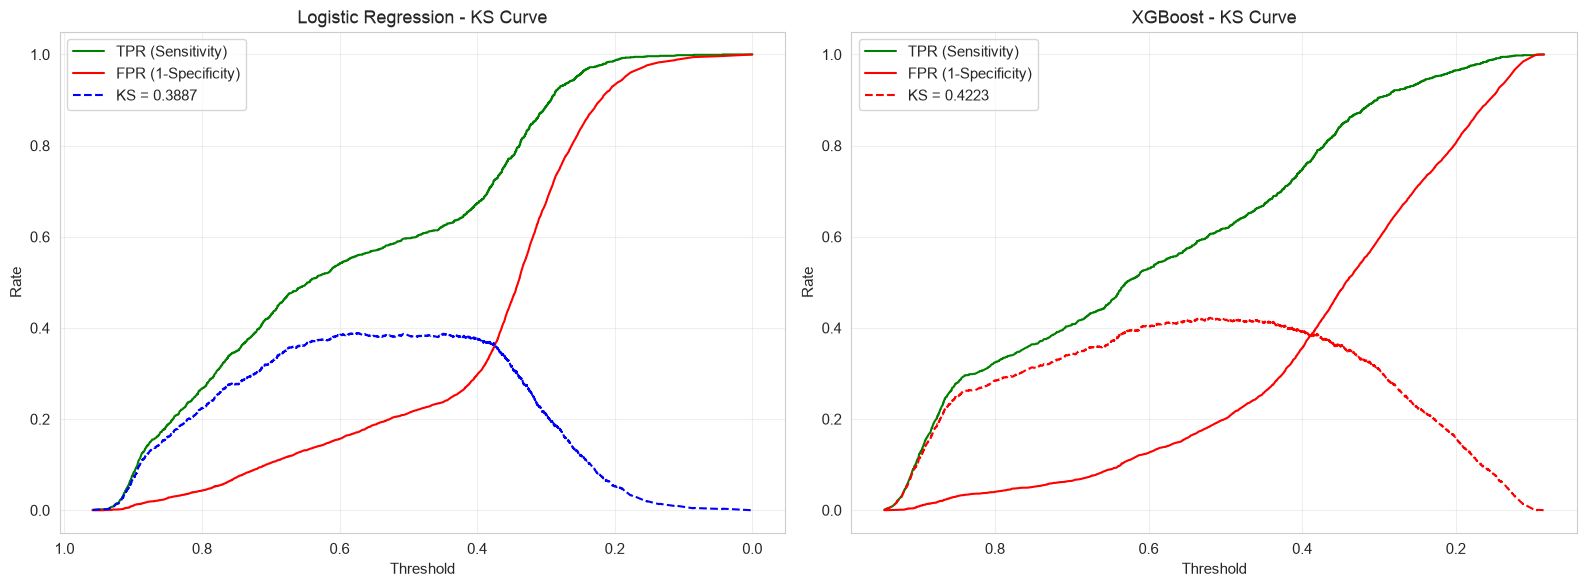

In [4]:
# KS Statistic
def calc_ks(y_true, y_prob):
    """Calculate the KS statistic."""
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    ks_stat = np.max(tpr - fpr)
    ks_threshold = thresholds[np.argmax(tpr - fpr)]
    return ks_stat, ks_threshold

ks_lr, ks_thresh_lr = calc_ks(y_test, y_prob_lr)
ks_xgb, ks_thresh_xgb = calc_ks(y_test, y_prob_xgb)

print(f"{'KS Statistic':<20} {ks_lr:>15.4f} {ks_xgb:>15.4f}")
print(f"{'KS Threshold':<20} {ks_thresh_lr:>15.4f} {ks_thresh_xgb:>15.4f}")

# KS Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, (y_prob, model_name, ks, color) in enumerate([
    (y_prob_lr, 'Logistic Regression', ks_lr, 'blue'),
    (y_prob_xgb, 'XGBoost', ks_xgb, 'red')
]):
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    axes[idx].plot(thresholds[1:], tpr[1:], label='TPR (Sensitivity)', color='green')
    axes[idx].plot(thresholds[1:], fpr[1:], label='FPR (1-Specificity)', color='red')
    axes[idx].plot(thresholds[1:], tpr[1:] - fpr[1:], label=f'KS = {ks:.4f}', color=color, linestyle='--')
    axes[idx].set_xlabel('Threshold')
    axes[idx].set_ylabel('Rate')
    axes[idx].set_title(f'{model_name} - KS Curve')
    axes[idx].legend()
    axes[idx].invert_xaxis()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/04_ks_curves.png', dpi=150, bbox_inches='tight')
plt.show()

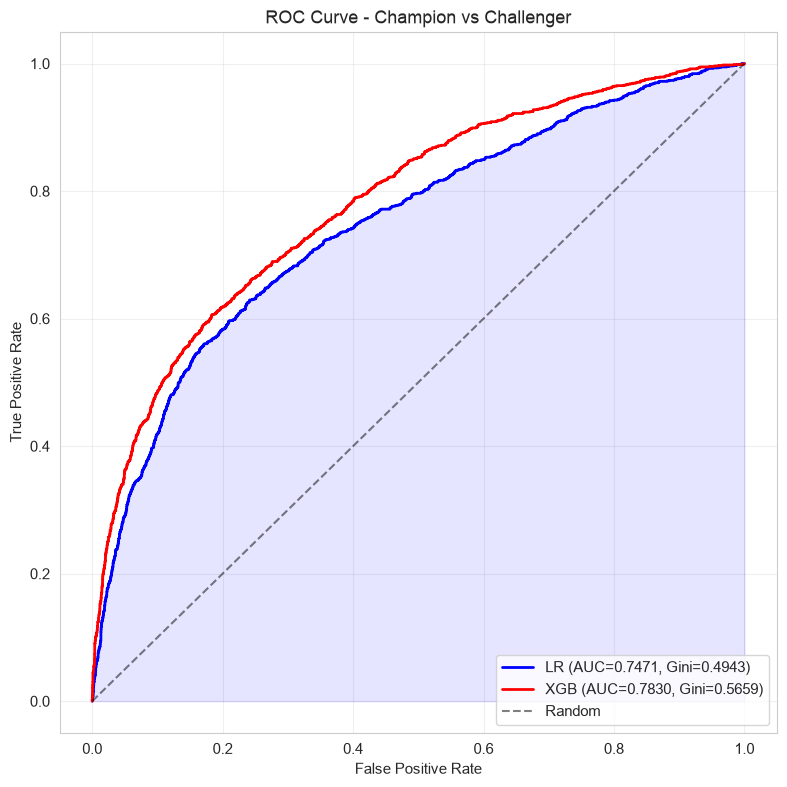

In [5]:
# ROC Curve comparison
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(fpr_lr, tpr_lr, 'b-', label=f'LR (AUC={auc_lr:.4f}, Gini={gini_lr:.4f})', linewidth=2)
ax.plot(fpr_xgb, tpr_xgb, 'r-', label=f'XGB (AUC={auc_xgb:.4f}, Gini={gini_xgb:.4f})', linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random')
ax.fill_between(fpr_lr, tpr_lr, alpha=0.1, color='blue')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve - Champion vs Challenger')
ax.legend(loc='lower right', fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/04_roc_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.3 Calibration Analysis

Calibration measures how closely the model's probability estimates match actual default rates. When a well-calibrated model predicts a 20% default probability, about 20% defaults should actually be observed in that group.

### Metrics:
- **Brier Score:** Mean squared error of the probability estimates (lower = better). It only means something next to the no-skill score of always predicting the default rate
- **Calibration Curve:** Predicted vs observed plot

In [6]:
# Brier Score, next to a no-skill forecast that always predicts the training default rate
base_rate = train_preds['y_true'].mean()
brier_lr = brier_score_loss(y_test, y_prob_lr)
brier_xgb = brier_score_loss(y_test, y_prob_xgb)
brier_base = brier_score_loss(y_test, np.full(len(y_test), base_rate))

print(f"=== Calibration Metrics ===")
print(f"Brier Score (LR):       {brier_lr:.4f}")
print(f"Brier Score (XGB):      {brier_xgb:.4f}")
print(f"Brier Score (no skill): {brier_base:.4f}")
print(f"\nObserved default rate: {np.mean(y_test):.4f}")
print(f"Mean predicted (LR):   {np.mean(y_prob_lr):.4f}")
print(f"Mean predicted (XGB):  {np.mean(y_prob_xgb):.4f}")

=== Calibration Metrics ===
Brier Score (LR):       0.1934
Brier Score (XGB):      0.1788
Brier Score (no skill): 0.1723

Observed default rate: 0.2212
Mean predicted (LR):   0.4372
Mean predicted (XGB):  0.4227


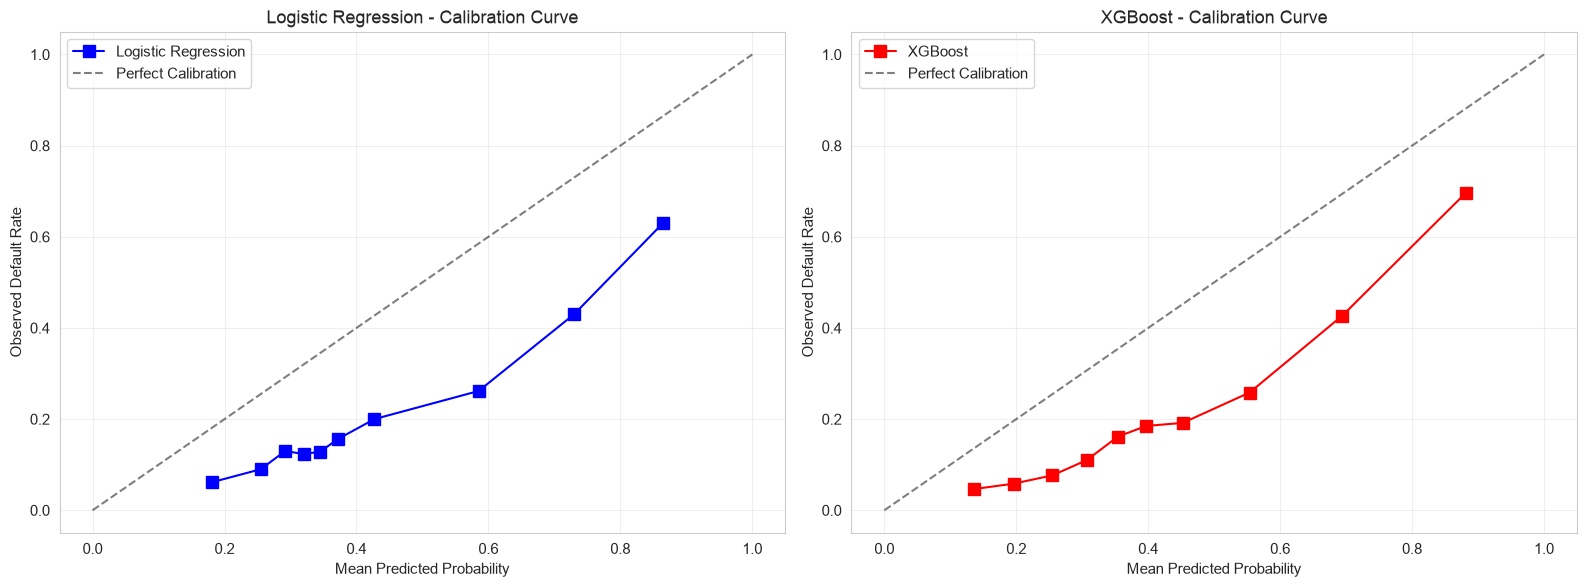

In [7]:
# Calibration Curve
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, (y_prob, model_name, color) in enumerate([
    (y_prob_lr, 'Logistic Regression', 'blue'),
    (y_prob_xgb, 'XGBoost', 'red')
]):
    fraction_pos, mean_pred = calibration_curve(y_test, y_prob, n_bins=10, strategy='quantile')

    axes[idx].plot(mean_pred, fraction_pos, 's-', color=color, label=model_name, markersize=8)
    axes[idx].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Perfect Calibration')
    axes[idx].set_xlabel('Mean Predicted Probability')
    axes[idx].set_ylabel('Observed Default Rate')
    axes[idx].set_title(f'{model_name} - Calibration Curve')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/04_calibration_curves.png', dpi=150, bbox_inches='tight')
plt.show()

### Recalibration

Both models are trained with class weights, which helps ranking but pushes the scores far above real default rates. A logistic fit on the log-odds of the training scores maps them back; the ranking does not change, so AUC stays the same.

In [8]:
from sklearn.linear_model import LogisticRegression

def recalibrate(score_train, y_train_true, score_test):
    def logit(p):
        p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
        return np.log(p / (1 - p)).reshape(-1, 1)
    return LogisticRegression(C=1e6).fit(logit(score_train), y_train_true).predict_proba(logit(score_test))[:, 1]

y_cal_lr = recalibrate(train_preds['y_prob_lr'].to_numpy(), train_preds['y_true'], y_prob_lr)
y_cal_xgb = recalibrate(train_preds['y_prob_xgb'].to_numpy(), train_preds['y_true'], y_prob_xgb)
brier_cal_lr, brier_cal_xgb = brier_score_loss(y_test, y_cal_lr), brier_score_loss(y_test, y_cal_xgb)

print(f"{'':>22} {'Brier':>8} {'Mean predicted':>15}")
print(f"{'No skill':>22} {brier_base:>8.4f} {base_rate:>15.4f}")
print(f"{'LR recalibrated':>22} {brier_cal_lr:>8.4f} {np.mean(y_cal_lr):>15.4f}")
print(f"{'XGB recalibrated':>22} {brier_cal_xgb:>8.4f} {np.mean(y_cal_xgb):>15.4f}")
print(f"Observed default rate: {np.mean(y_test):.4f}")

                          Brier  Mean predicted
              No skill   0.1723          0.2212
       LR recalibrated   0.1435          0.2196
      XGB recalibrated   0.1352          0.2217
Observed default rate: 0.2212


In [9]:
# Detailed calibration table
def calibration_table(y_true, y_prob, n_bins=10, model_name='Model'):
    """Build a detailed calibration table."""
    df_cal = pd.DataFrame({'y_true': y_true.values, 'y_prob': y_prob.values})
    df_cal['decile'] = pd.qcut(df_cal['y_prob'], q=n_bins, labels=False, duplicates='drop') + 1

    table = df_cal.groupby('decile').agg(
        n=('y_true', 'count'),
        n_default=('y_true', 'sum'),
        avg_predicted=('y_prob', 'mean'),
        observed_rate=('y_true', 'mean'),
        min_prob=('y_prob', 'min'),
        max_prob=('y_prob', 'max')
    ).round(4)

    table['predicted_rate'] = table['avg_predicted']
    table['cal_error'] = (table['observed_rate'] - table['predicted_rate']).abs()
    return table

print("=== Logistic Regression - Calibration Table ===")
cal_lr = calibration_table(y_test, y_prob_lr, model_name='LR')
print(cal_lr.to_string())

print("\n=== XGBoost - Calibration Table ===")
cal_xgb = calibration_table(y_test, y_prob_xgb, model_name='XGB')
print(cal_xgb.to_string())

=== Logistic Regression - Calibration Table ===
          n  n_default  avg_predicted  observed_rate  min_prob  max_prob  predicted_rate  cal_error
decile                                                                                             
1       600         37         0.1814         0.0617    0.0000    0.2310          0.1814     0.1197
2       600         54         0.2548         0.0900    0.2312    0.2759          0.2548     0.1648
3       600         78         0.2920         0.1300    0.2760    0.3065          0.2920     0.1620
4       600         74         0.3200         0.1233    0.3066    0.3328          0.3200     0.1967
5       600         77         0.3447         0.1283    0.3329    0.3582          0.3447     0.2164
6       600         94         0.3724         0.1567    0.3583    0.3893          0.3724     0.2157
7       600        120         0.4272         0.2000    0.3894    0.4958          0.4272     0.2272
8       600        157         0.5852         0.2617

## 4.4 Decile Analysis

Decile analysis shows how effective the model's risk ranking is. The actual default rate should be highest in the riskiest 10% band, and the default rate should fall as risk decreases. This analysis is critical for assessing the model's practical usability.

In [10]:
def decile_analysis(y_true, y_prob, model_name='Model'):
    """Decile-level performance analysis."""
    df_dec = pd.DataFrame({'y_true': y_true.values, 'y_prob': y_prob.values})
    df_dec['decile'] = pd.qcut(df_dec['y_prob'], q=10, labels=False, duplicates='drop')
    df_dec['decile'] = 10 - df_dec['decile']  # 1 = riskiest

    table = df_dec.groupby('decile').agg(
        n=('y_true', 'count'),
        n_default=('y_true', 'sum'),
        default_rate=('y_true', 'mean'),
        avg_score=('y_prob', 'mean'),
        min_score=('y_prob', 'min'),
        max_score=('y_prob', 'max')
    )

    table['cum_default'] = table['n_default'].cumsum()
    table['cum_total'] = table['n'].cumsum()
    table['cum_default_rate'] = table['cum_default'] / table['cum_default'].iloc[-1]
    table['cum_non_default'] = (table['n'] - table['n_default']).cumsum()
    table['cum_non_default_rate'] = table['cum_non_default'] / table['cum_non_default'].iloc[-1]
    table['lift'] = table['default_rate'] / y_true.mean()

    return table.round(4)

dec_lr = decile_analysis(y_test, y_prob_lr, 'LR')
dec_xgb = decile_analysis(y_test, y_prob_xgb, 'XGB')

print("=== Logistic Regression - Decile Analysis ===")
print(dec_lr[['n', 'n_default', 'default_rate', 'cum_default_rate', 'lift']].to_string())

print("\n=== XGBoost - Decile Analysis ===")
print(dec_xgb[['n', 'n_default', 'default_rate', 'cum_default_rate', 'lift']].to_string())

=== Logistic Regression - Decile Analysis ===
          n  n_default  default_rate  cum_default_rate    lift
decile                                                        
1       600        378        0.6300            0.2849  2.8485
2       600        258        0.4300            0.4793  1.9442
3       600        157        0.2617            0.5976  1.1831
4       600        120        0.2000            0.6880  0.9043
5       600         94        0.1567            0.7589  0.7084
6       600         77        0.1283            0.8169  0.5803
7       600         74        0.1233            0.8726  0.5576
8       600         78        0.1300            0.9314  0.5878
9       600         54        0.0900            0.9721  0.4069
10      600         37        0.0617            1.0000  0.2788

=== XGBoost - Decile Analysis ===
          n  n_default  default_rate  cum_default_rate    lift
decile                                                        
1       600        418        0.6967 

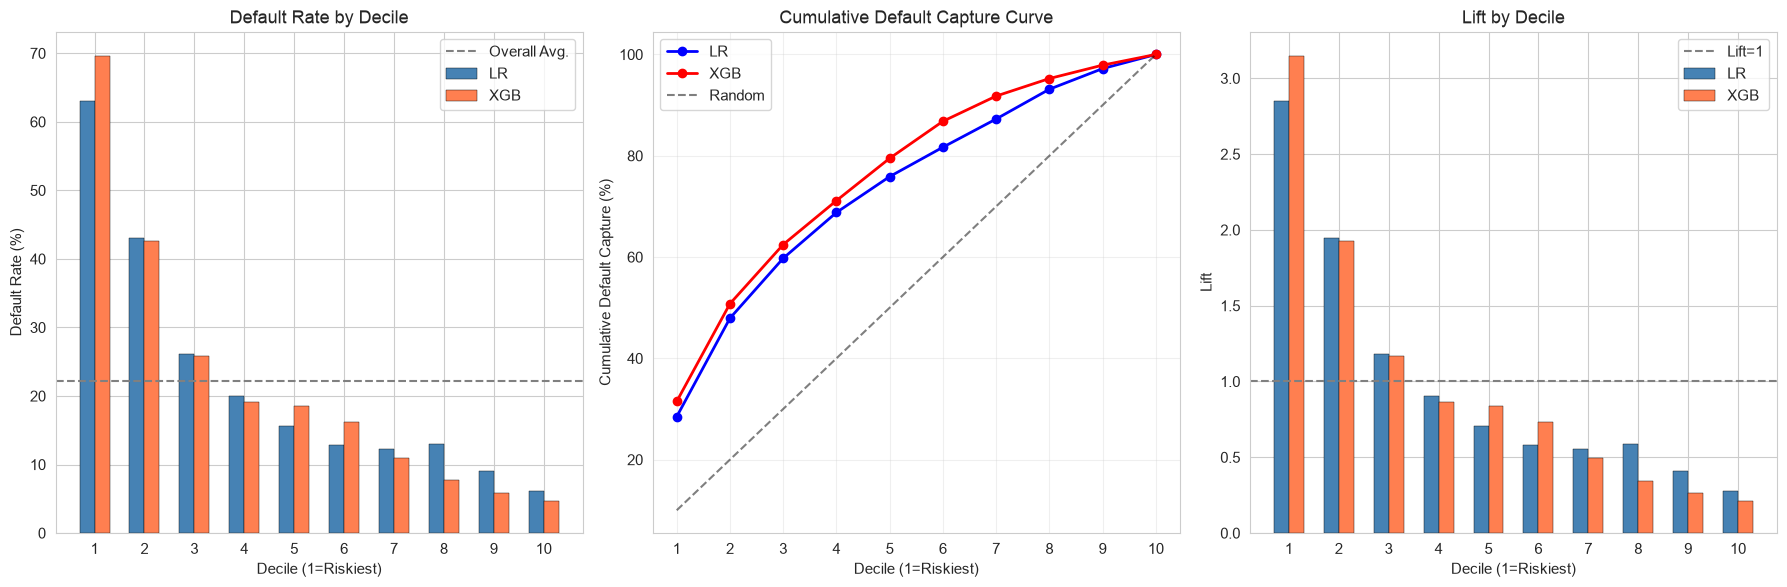

In [11]:
# Decile plots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Decile default rate
x = range(1, 11)
axes[0].bar(np.array(list(x)) - 0.15, dec_lr['default_rate'] * 100, width=0.3,
            label='LR', color='steelblue', edgecolor='black', linewidth=0.3)
axes[0].bar(np.array(list(x)) + 0.15, dec_xgb['default_rate'] * 100, width=0.3,
            label='XGB', color='coral', edgecolor='black', linewidth=0.3)
axes[0].axhline(y=y_test.mean() * 100, color='gray', linestyle='--', label='Overall Avg.')
axes[0].set_xlabel('Decile (1=Riskiest)')
axes[0].set_ylabel('Default Rate (%)')
axes[0].set_title('Default Rate by Decile')
axes[0].legend()
axes[0].set_xticks(list(x))

# 2. Cumulative default capture
axes[1].plot(x, dec_lr['cum_default_rate'] * 100, 'bo-', label='LR', linewidth=2)
axes[1].plot(x, dec_xgb['cum_default_rate'] * 100, 'ro-', label='XGB', linewidth=2)
axes[1].plot(x, np.linspace(10, 100, 10), 'k--', alpha=0.5, label='Random')
axes[1].set_xlabel('Decile (1=Riskiest)')
axes[1].set_ylabel('Cumulative Default Capture (%)')
axes[1].set_title('Cumulative Default Capture Curve')
axes[1].legend()
axes[1].set_xticks(list(x))
axes[1].grid(True, alpha=0.3)

# 3. Lift
axes[2].bar(np.array(list(x)) - 0.15, dec_lr['lift'], width=0.3,
            label='LR', color='steelblue', edgecolor='black', linewidth=0.3)
axes[2].bar(np.array(list(x)) + 0.15, dec_xgb['lift'], width=0.3,
            label='XGB', color='coral', edgecolor='black', linewidth=0.3)
axes[2].axhline(y=1.0, color='gray', linestyle='--', label='Lift=1')
axes[2].set_xlabel('Decile (1=Riskiest)')
axes[2].set_ylabel('Lift')
axes[2].set_title('Lift by Decile')
axes[2].legend()
axes[2].set_xticks(list(x))

plt.tight_layout()
plt.savefig('../reports/04_decile_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.5 Segment-Level Performance Analysis

A critical component of model validation is assessing whether the model performs consistently across different customer segments. A drop in performance in particular segments may point to model bias or under-representation.

In [12]:
def segment_performance(y_true, y_prob, segment_col, segment_name):
    """Calculate AUC by segment."""
    results = []
    for seg_val in sorted(segment_col.unique()):
        mask = segment_col == seg_val
        if mask.sum() < 30 or y_true[mask].nunique() < 2:
            continue
        auc = roc_auc_score(y_true[mask], y_prob[mask])
        results.append({
            'Segment': seg_val,
            'N': mask.sum(),
            'Default Rate': y_true[mask].mean(),
            'AUC': auc
        })
    return pd.DataFrame(results)

# Add the segment information to the test data
test_data = df_full.loc[predictions.index].copy()

# Gender
sex_map = {1: 'Male', 2: 'Female'}
test_data['SEX_LABEL'] = test_data['SEX'].map(sex_map)

seg_sex_lr = segment_performance(y_test, y_prob_lr, test_data['SEX_LABEL'], 'Gender')
seg_sex_xgb = segment_performance(y_test, y_prob_xgb, test_data['SEX_LABEL'], 'Gender')

print("=== AUC by Gender ===")
print(f"{'Gender':<12} {'N':>8} {'Default%':>10} {'LR AUC':>10} {'XGB AUC':>10}")
for i in range(len(seg_sex_lr)):
    print(f"{seg_sex_lr.iloc[i]['Segment']:<12} {int(seg_sex_lr.iloc[i]['N']):>8,} "
          f"{seg_sex_lr.iloc[i]['Default Rate']*100:>9.2f}% "
          f"{seg_sex_lr.iloc[i]['AUC']:>10.4f} {seg_sex_xgb.iloc[i]['AUC']:>10.4f}")

=== AUC by Gender ===
Gender              N   Default%     LR AUC    XGB AUC
Female          3,598     21.29%     0.7433     0.7870
Male            2,402     23.36%     0.7504     0.7767


In [13]:
# Education level
edu_map = {1: 'Graduate', 2: 'University', 3: 'High School', 4: 'Other'}
test_data['EDU_LABEL'] = test_data['EDUCATION'].map(edu_map)

seg_edu_lr = segment_performance(y_test, y_prob_lr, test_data['EDU_LABEL'], 'Education')
seg_edu_xgb = segment_performance(y_test, y_prob_xgb, test_data['EDU_LABEL'], 'Education')

print("=== AUC by Education Level ===")
print(f"{'Education':<14} {'N':>8} {'Default%':>10} {'LR AUC':>10} {'XGB AUC':>10}")
for i in range(len(seg_edu_lr)):
    print(f"{seg_edu_lr.iloc[i]['Segment']:<14} {int(seg_edu_lr.iloc[i]['N']):>8,} "
          f"{seg_edu_lr.iloc[i]['Default Rate']*100:>9.2f}% "
          f"{seg_edu_lr.iloc[i]['AUC']:>10.4f} {seg_edu_xgb.iloc[i]['AUC']:>10.4f}")

=== AUC by Education Level ===
Education             N   Default%     LR AUC    XGB AUC
Graduate          2,130     19.01%     0.7523     0.8010
High School       1,014     25.74%     0.7085     0.7323
Other                82      6.10%     0.6286     0.6571
University        2,774     23.65%     0.7510     0.7818


In [14]:
# Age group
age_bins = pd.cut(test_data['AGE'], bins=[20, 30, 40, 50, 80], labels=['20-29', '30-39', '40-49', '50+'])
seg_age_lr = segment_performance(y_test, y_prob_lr, age_bins, 'Age')
seg_age_xgb = segment_performance(y_test, y_prob_xgb, age_bins, 'Age')

print("=== AUC by Age Group ===")
print(f"{'Age Group':<12} {'N':>8} {'Default%':>10} {'LR AUC':>10} {'XGB AUC':>10}")
for i in range(len(seg_age_lr)):
    print(f"{seg_age_lr.iloc[i]['Segment']:<12} {int(seg_age_lr.iloc[i]['N']):>8,} "
          f"{seg_age_lr.iloc[i]['Default Rate']*100:>9.2f}% "
          f"{seg_age_lr.iloc[i]['AUC']:>10.4f} {seg_age_xgb.iloc[i]['AUC']:>10.4f}")

=== AUC by Age Group ===
Age Group           N   Default%     LR AUC    XGB AUC
20-29           2,181     21.96%     0.7607     0.7916
30-39           2,105     20.95%     0.7388     0.7827
40-49           1,243     23.49%     0.7268     0.7658
50+               471     24.42%     0.7687     0.7924


In [15]:
# Limit band
limit_bins = pd.cut(test_data['LIMIT_BAL'],
                    bins=[0, 50000, 100000, 200000, 500000, float('inf')],
                    labels=['<50K', '50-100K', '100-200K', '200-500K', '500K+'])
seg_lim_lr = segment_performance(y_test, y_prob_lr, limit_bins, 'Limit')
seg_lim_xgb = segment_performance(y_test, y_prob_xgb, limit_bins, 'Limit')

print("=== AUC by Limit Band ===")
print(f"{'Limit Band':<14} {'N':>8} {'Default%':>10} {'LR AUC':>10} {'XGB AUC':>10}")
for i in range(len(seg_lim_lr)):
    print(f"{seg_lim_lr.iloc[i]['Segment']:<14} {int(seg_lim_lr.iloc[i]['N']):>8,} "
          f"{seg_lim_lr.iloc[i]['Default Rate']*100:>9.2f}% "
          f"{seg_lim_lr.iloc[i]['AUC']:>10.4f} {seg_lim_xgb.iloc[i]['AUC']:>10.4f}")

=== AUC by Limit Band ===
Limit Band            N   Default%     LR AUC    XGB AUC
100-200K          1,530     18.76%     0.7283     0.7538
200-500K          1,895     16.83%     0.7329     0.7916
50-100K           1,003     25.32%     0.7479     0.7899
500K+                42      9.52%     0.9013     0.8289
<50K              1,530     30.26%     0.7369     0.7567


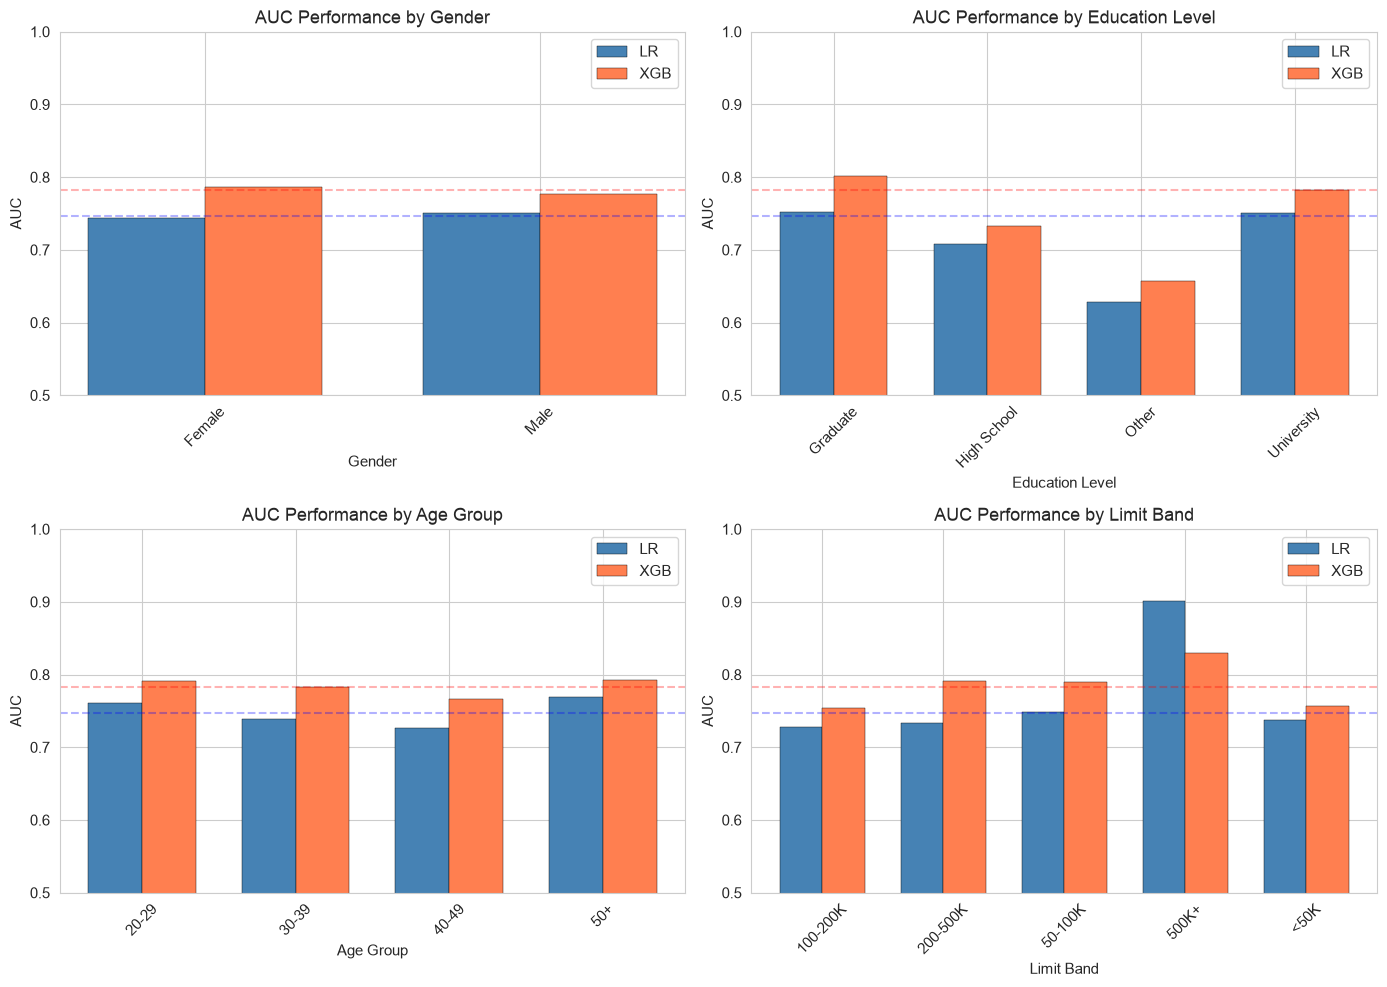

In [16]:
# Segment performance visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

segments = [
    (seg_sex_lr, seg_sex_xgb, 'Gender'),
    (seg_edu_lr, seg_edu_xgb, 'Education Level'),
    (seg_age_lr, seg_age_xgb, 'Age Group'),
    (seg_lim_lr, seg_lim_xgb, 'Limit Band')
]

for idx, (seg_lr, seg_xgb, title) in enumerate(segments):
    ax = axes[idx // 2][idx % 2]
    x_pos = np.arange(len(seg_lr))
    width = 0.35

    ax.bar(x_pos - width/2, seg_lr['AUC'], width, label='LR', color='steelblue', edgecolor='black', linewidth=0.3)
    ax.bar(x_pos + width/2, seg_xgb['AUC'], width, label='XGB', color='coral', edgecolor='black', linewidth=0.3)
    ax.axhline(y=auc_lr, color='blue', linestyle='--', alpha=0.3)
    ax.axhline(y=auc_xgb, color='red', linestyle='--', alpha=0.3)
    ax.set_xlabel(title)
    ax.set_ylabel('AUC')
    ax.set_title(f'AUC Performance by {title}')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(seg_lr['Segment'], rotation=45)
    ax.legend()
    ax.set_ylim(0.5, 1.0)

plt.tight_layout()
plt.savefig('../reports/04_segment_performance.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.6 Stability Analysis (Population Stability Index - PSI)

PSI measures the distribution shift between the population the model was trained on and the population it is applied to.

### Assessment Criteria:
- **PSI < 0.10:** Stable, no change
- **PSI 0.10 - 0.25:** Slight shift, should be monitored
- **PSI > 0.25:** Significant shift, the model should be re-assessed

**Note:** This data has no time axis and the test set is a random sample, so PSI here checks that the split is sound. It says nothing about drift over time; in production the same function would compare the development sample with each new period.

In [17]:
def calculate_psi(expected, actual, n_bins=10):
    """Calculate the Population Stability Index."""
    # Create the quantile bins (from the expected distribution)
    bins = np.quantile(expected, np.linspace(0, 1, n_bins + 1))
    bins[0] = -np.inf
    bins[-1] = np.inf

    # Calculate the frequencies
    expected_counts = np.histogram(expected, bins=bins)[0]
    actual_counts = np.histogram(actual, bins=bins)[0]

    # Proportions (zero guard with a minimum of 0.001)
    expected_pct = np.maximum(expected_counts / len(expected), 0.001)
    actual_pct = np.maximum(actual_counts / len(actual), 0.001)

    # PSI components
    psi_components = (actual_pct - expected_pct) * np.log(actual_pct / expected_pct)

    return psi_components.sum(), pd.DataFrame({
        'Bin': range(1, n_bins + 1),
        'Train (%)': expected_pct * 100,
        'Test (%)': actual_pct * 100,
        'PSI Component': psi_components
    })

# LR score PSI
psi_lr, psi_detail_lr = calculate_psi(
    train_preds['y_prob_lr'].values,
    predictions['y_prob_lr'].values
)

# XGB score PSI
psi_xgb, psi_detail_xgb = calculate_psi(
    train_preds['y_prob_xgb'].values,
    predictions['y_prob_xgb'].values
)

print(f"=== Population Stability Index (Score Distribution) ===")
print(f"LR PSI:  {psi_lr:.4f} {'✓ Stable' if psi_lr < 0.10 else '⚠ Monitor' if psi_lr < 0.25 else '✗ Shift!'}")
print(f"XGB PSI: {psi_xgb:.4f} {'✓ Stable' if psi_xgb < 0.10 else '⚠ Monitor' if psi_xgb < 0.25 else '✗ Shift!'}")

=== Population Stability Index (Score Distribution) ===
LR PSI:  0.0012 ✓ Stable
XGB PSI: 0.0007 ✓ Stable


In [18]:
# Feature PSI
print("=== Feature-Level PSI (Feature Stability) ===")
train_features = df_full.loc[train_preds.index, feature_list]

feature_psi = []
for col in feature_list:
    psi_val, _ = calculate_psi(train_features[col].values, test_features[col].values)
    feature_psi.append({'Feature': col, 'PSI': psi_val})

feature_psi_df = pd.DataFrame(feature_psi).sort_values('PSI', ascending=False)
feature_psi_df['Status'] = feature_psi_df['PSI'].apply(
    lambda x: 'Stable' if x < 0.10 else 'Monitor' if x < 0.25 else 'Shift!'
)

print(feature_psi_df.to_string(index=False))

# Warning
unstable = feature_psi_df[feature_psi_df['PSI'] >= 0.10]
if len(unstable) > 0:
    print(f"\n⚠ PSI >= 0.10 detected in {len(unstable)} features!")
else:
    print("\n✓ All features are stable (PSI < 0.10)")

=== Feature-Level PSI (Feature Stability) ===
          Feature      PSI Status
              AGE 0.002945 Stable
        BILL_AMT4 0.002701 Stable
   AVG_UTIL_RATIO 0.002385 Stable
         PAY_AMT1 0.002211 Stable
        BILL_AMT1 0.002062 Stable
          AVG_PAY 0.001995 Stable
        TOTAL_PAY 0.001995 Stable
        PAY_TREND 0.001576 Stable
        LIMIT_BAL 0.001576 Stable
PAY_TO_BILL_RATIO 0.001389 Stable
        BILL_AMT3 0.001298 Stable
       UTIL_RATIO 0.001283 Stable
  MAX_DELINQUENCY 0.001223 Stable
         PAY_AMT2 0.001123 Stable
         PAY_AMT5 0.001099 Stable
DELINQUENCY_TREND 0.001090 Stable
            PAY_0 0.001087 Stable
         PAY_AMT4 0.001082 Stable
        BILL_AMT2 0.001051 Stable
       BILL_TREND 0.001016 Stable
        BILL_AMT5 0.000901 Stable
  AVG_DELINQUENCY 0.000807 Stable
         PAY_AMT6 0.000741 Stable
       TOTAL_BILL 0.000665 Stable
         AVG_BILL 0.000665 Stable
         PAY_AMT3 0.000567 Stable
DELINQUENCY_COUNT 0.000567 Stable
 N

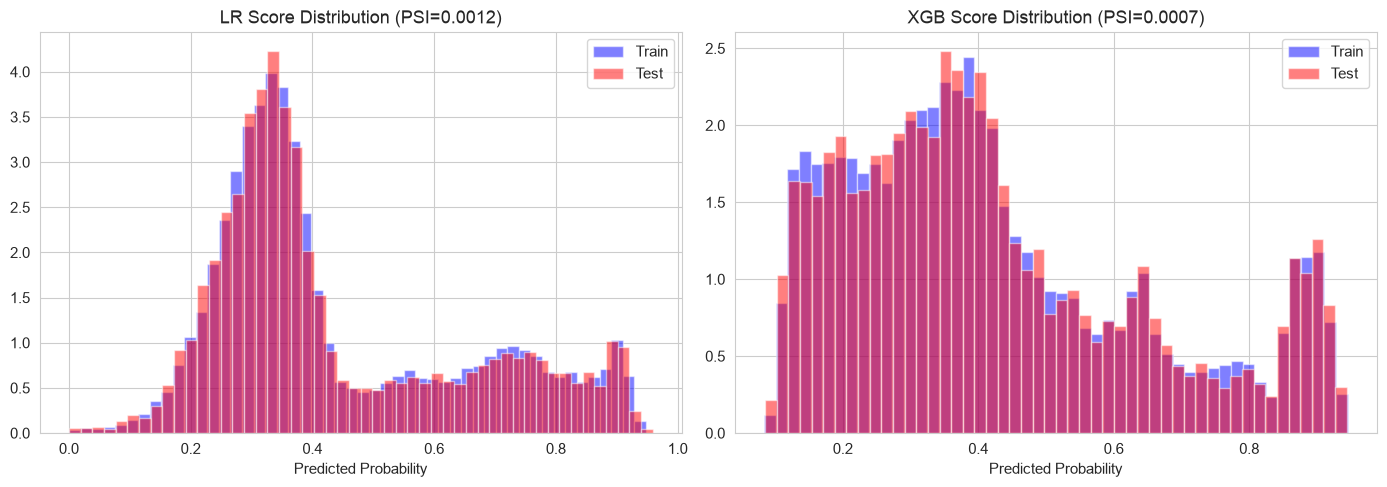

In [19]:
# Score distribution comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(train_preds['y_prob_lr'], bins=50, alpha=0.5, density=True, label='Train', color='blue')
axes[0].hist(predictions['y_prob_lr'], bins=50, alpha=0.5, density=True, label='Test', color='red')
axes[0].set_title(f'LR Score Distribution (PSI={psi_lr:.4f})')
axes[0].set_xlabel('Predicted Probability')
axes[0].legend()

axes[1].hist(train_preds['y_prob_xgb'], bins=50, alpha=0.5, density=True, label='Train', color='blue')
axes[1].hist(predictions['y_prob_xgb'], bins=50, alpha=0.5, density=True, label='Test', color='red')
axes[1].set_title(f'XGB Score Distribution (PSI={psi_xgb:.4f})')
axes[1].set_xlabel('Predicted Probability')
axes[1].legend()

plt.tight_layout()
plt.savefig('../reports/04_score_stability.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.7 Train-Test Performance Gap (Overfit Check)

In [20]:
train_auc_lr = roc_auc_score(train_preds['y_true'], train_preds['y_prob_lr'])
train_auc_xgb = roc_auc_score(train_preds['y_true'], train_preds['y_prob_xgb'])

print("=== Train vs Test AUC Comparison ===")
print(f"{'':>20} {'Train AUC':>12} {'Test AUC':>12} {'Gap':>10} {'Assessment':>20}")
print(f"{'-'*74}")

gap_lr = train_auc_lr - auc_lr
gap_xgb = train_auc_xgb - auc_xgb

eval_lr = 'Acceptable' if gap_lr < 0.03 else 'Monitor' if gap_lr < 0.05 else 'Overfit risk'
eval_xgb = 'Acceptable' if gap_xgb < 0.03 else 'Monitor' if gap_xgb < 0.05 else 'Overfit risk'

print(f"{'Logistic Reg':>20} {train_auc_lr:>12.4f} {auc_lr:>12.4f} {gap_lr:>10.4f} {eval_lr:>20}")
print(f"{'XGBoost':>20} {train_auc_xgb:>12.4f} {auc_xgb:>12.4f} {gap_xgb:>10.4f} {eval_xgb:>20}")

=== Train vs Test AUC Comparison ===
                        Train AUC     Test AUC        Gap           Assessment
--------------------------------------------------------------------------
        Logistic Reg       0.7645       0.7471     0.0173           Acceptable
             XGBoost       0.8193       0.7830     0.0363              Monitor


## 4.8 Model Interpretation (SHAP Analysis)

SHAP (SHapley Additive exPlanations) values measure the contribution of each feature to individual predictions. This analysis is important for showing that the model is not a "black box" and for meeting regulatory expectations.

In [21]:
# SHAP values (for XGBoost — tree-based SHAP is faster)
explainer = shap.TreeExplainer(xgb_model)

# Compute for the first 2000 observations of the test set (for performance)
sample_size = min(2000, len(test_features_scaled))
X_sample = test_features_scaled.iloc[:sample_size]
shap_values = explainer.shap_values(X_sample)

print(f"SHAP values computed ({sample_size} observations)")

SHAP values computed (2000 observations)


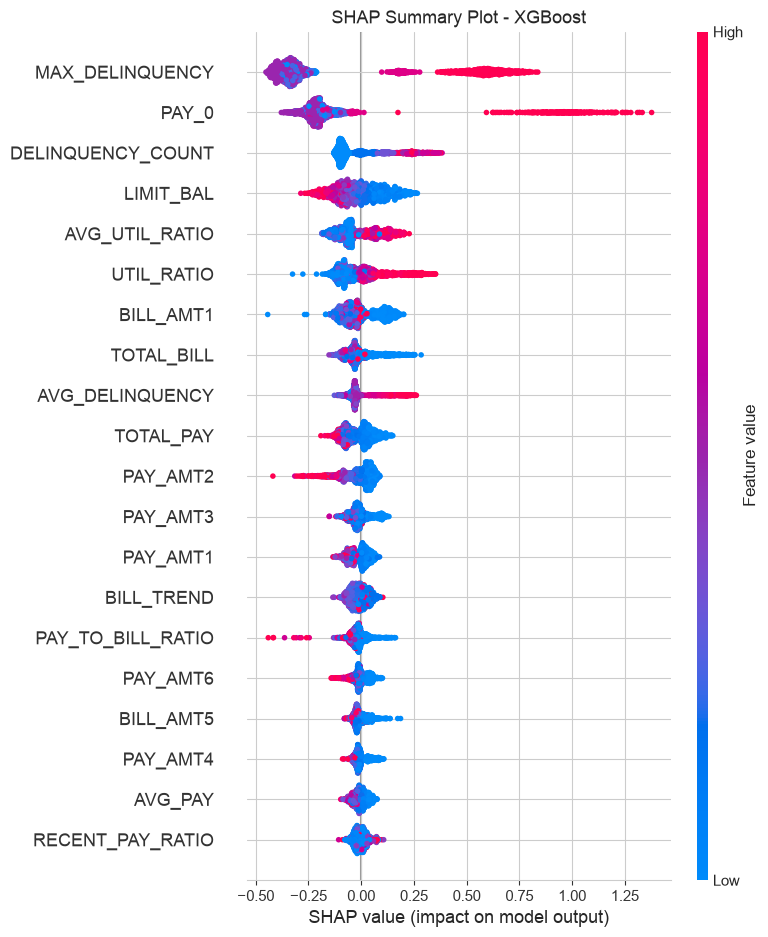

In [22]:
# SHAP Summary Plot (Bee Swarm)
plt.figure(figsize=(12, 10))
shap.summary_plot(shap_values, X_sample, feature_names=feature_list,
                  show=False, max_display=20)
plt.title('SHAP Summary Plot - XGBoost')
plt.tight_layout()
plt.savefig('../reports/04_shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

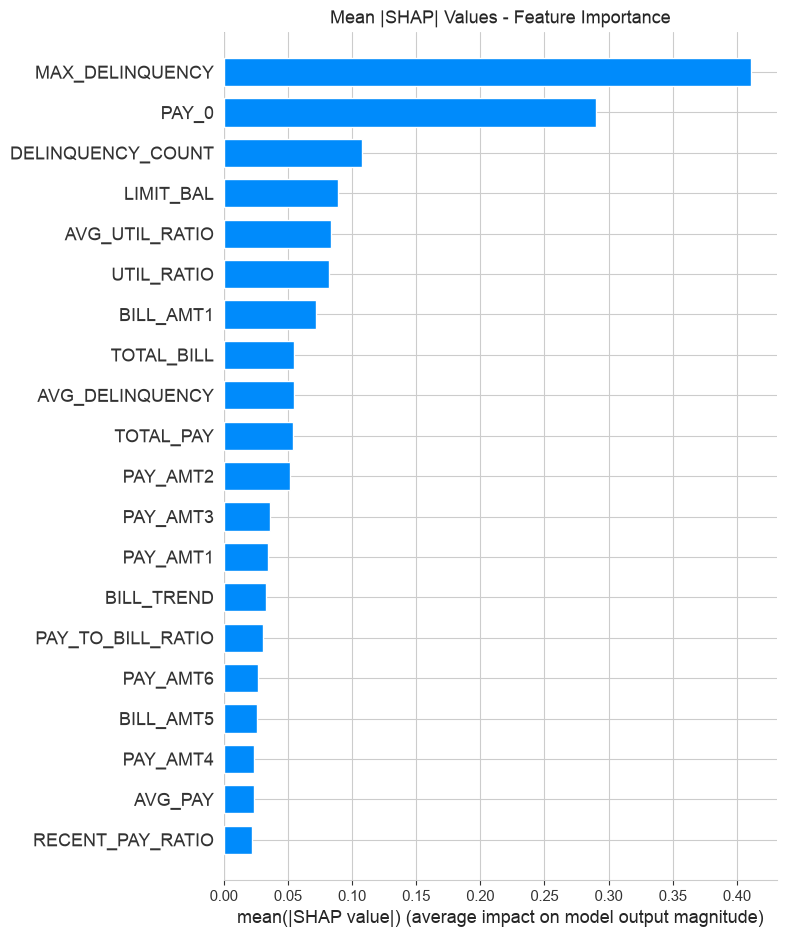

In [23]:
# SHAP Bar Plot (mean absolute SHAP)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_sample, feature_names=feature_list,
                  plot_type='bar', show=False, max_display=20)
plt.title('Mean |SHAP| Values - Feature Importance')
plt.tight_layout()
plt.savefig('../reports/04_shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()

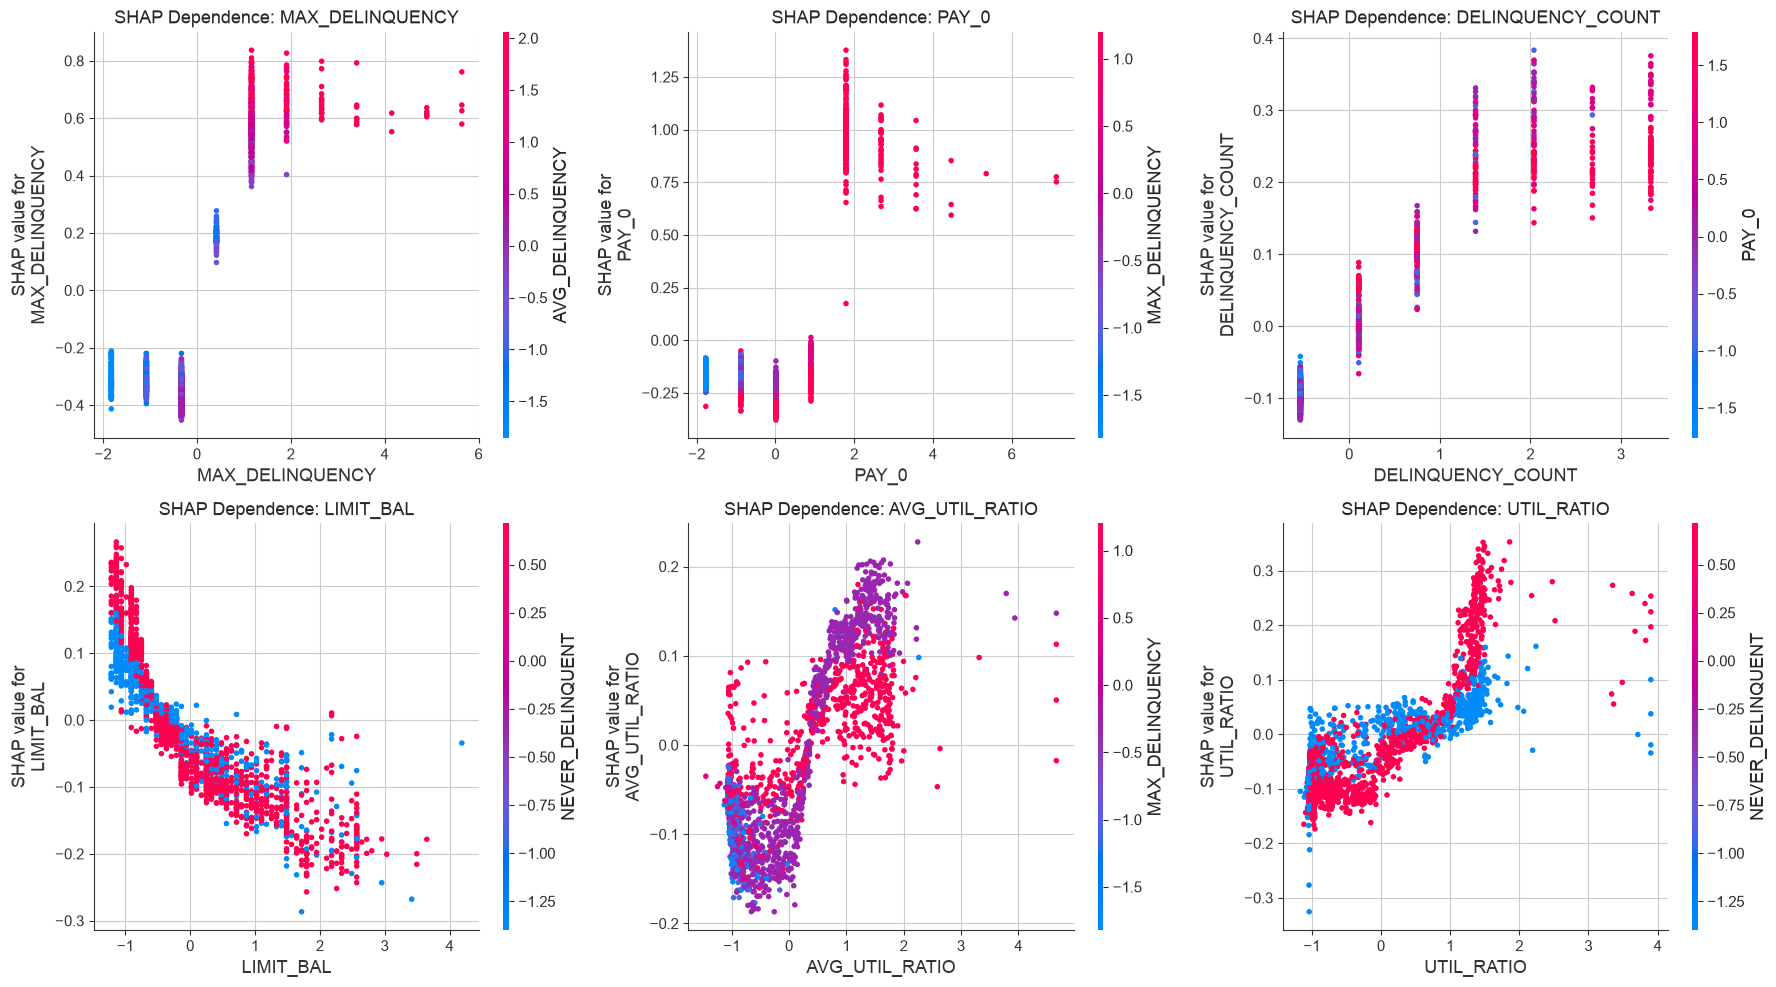

In [24]:
# SHAP dependence plot for the top 6 features
top_features = pd.Series(np.abs(shap_values).mean(axis=0),
                         index=feature_list).sort_values(ascending=False).head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for idx, feat in enumerate(top_features):
    ax = axes[idx // 3][idx % 3]
    feat_idx = feature_list.index(feat)
    shap.dependence_plot(feat_idx, shap_values, X_sample,
                         feature_names=feature_list, ax=ax, show=False)
    ax.set_title(f'SHAP Dependence: {feat}')

plt.tight_layout()
plt.savefig('../reports/04_shap_dependence.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.9 Champion vs Challenger Assessment

In this section, we assess whether there is a statistically significant difference between the champion model (Logistic Regression) and the challenger model (XGBoost).

In [25]:
# DeLong test approach (confidence interval for the AUC difference via bootstrap)
def bootstrap_auc_diff(y_true, y_prob_1, y_prob_2, n_bootstrap=1000, alpha=0.05):
    """Calculate the confidence interval for the AUC difference of two models via bootstrap."""
    np.random.seed(42)
    n = len(y_true)
    diffs = []

    for _ in range(n_bootstrap):
        idx = np.random.choice(n, size=n, replace=True)
        y_b = y_true.values[idx]
        if len(np.unique(y_b)) < 2:
            continue
        auc_1 = roc_auc_score(y_b, y_prob_1.values[idx])
        auc_2 = roc_auc_score(y_b, y_prob_2.values[idx])
        diffs.append(auc_2 - auc_1)

    diffs = np.array(diffs)
    ci_lower = np.percentile(diffs, alpha/2 * 100)
    ci_upper = np.percentile(diffs, (1 - alpha/2) * 100)

    return diffs.mean(), ci_lower, ci_upper

mean_diff, ci_low, ci_high = bootstrap_auc_diff(y_test, y_prob_lr, y_prob_xgb)

print("=== Champion (LR) vs Challenger (XGB) - AUC Difference Test ===")
print(f"LR AUC:  {auc_lr:.4f}")
print(f"XGB AUC: {auc_xgb:.4f}")
print(f"Difference (XGB - LR): {mean_diff:.4f}")
print(f"95% Confidence Interval: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"\nInterpretation: ", end='')
if ci_low > 0:
    print("XGBoost is statistically significantly better.")
elif ci_high < 0:
    print("Logistic Regression is statistically significantly better.")
else:
    print("There is no statistically significant difference between the two models.")

=== Champion (LR) vs Challenger (XGB) - AUC Difference Test ===
LR AUC:  0.7471
XGB AUC: 0.7830
Difference (XGB - LR): 0.0360
95% Confidence Interval: [0.0269, 0.0455]

Interpretation: XGBoost is statistically significantly better.


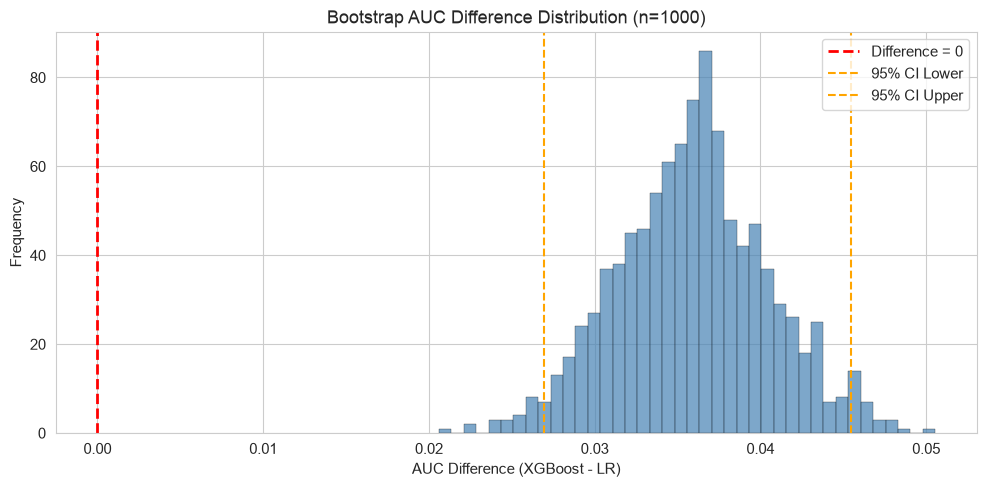

In [26]:
# Bootstrap distribution plot
fig, ax = plt.subplots(figsize=(10, 5))
diffs_full = []
np.random.seed(42)
n = len(y_test)
for _ in range(1000):
    idx = np.random.choice(n, size=n, replace=True)
    y_b = y_test.values[idx]
    if len(np.unique(y_b)) < 2:
        continue
    auc_1 = roc_auc_score(y_b, y_prob_lr.values[idx])
    auc_2 = roc_auc_score(y_b, y_prob_xgb.values[idx])
    diffs_full.append(auc_2 - auc_1)

ax.hist(diffs_full, bins=40, color='steelblue', edgecolor='black', linewidth=0.3, alpha=0.7)
ax.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Difference = 0')
ax.axvline(x=np.percentile(diffs_full, 2.5), color='orange', linestyle='--', label='95% CI Lower')
ax.axvline(x=np.percentile(diffs_full, 97.5), color='orange', linestyle='--', label='95% CI Upper')
ax.set_xlabel('AUC Difference (XGBoost - LR)')
ax.set_ylabel('Frequency')
ax.set_title('Bootstrap AUC Difference Distribution (n=1000)')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/04_bootstrap_auc_diff.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.10 Validation Summary Table

In [27]:
# Collect all metrics in a single table
summary_data = {
    'Metric': [
        'ROC-AUC (Test)',
        'Gini Coefficient',
        'KS Statistic',
        'Brier Score (raw)',
        'Brier Score (recalibrated)',
        'Train-Test AUC Gap',
        'Score PSI',
        'CV Mean AUC'
    ],
    'Logistic Regression': [
        f"{auc_lr:.4f}",
        f"{gini_lr:.4f}",
        f"{ks_lr:.4f}",
        f"{brier_lr:.4f}",
        f"{brier_cal_lr:.4f}",
        f"{gap_lr:.4f}",
        f"{psi_lr:.4f}",
        f"{float(meta.loc['lr_cv_auc', 'value']):.4f}"
    ],
    'XGBoost': [
        f"{auc_xgb:.4f}",
        f"{gini_xgb:.4f}",
        f"{ks_xgb:.4f}",
        f"{brier_xgb:.4f}",
        f"{brier_cal_xgb:.4f}",
        f"{gap_xgb:.4f}",
        f"{psi_xgb:.4f}",
        f"{float(meta.loc['xgb_cv_auc', 'value']):.4f}"
    ],
    'Criterion': [
        '> 0.70 acceptable',
        '> 0.40 good',
        '> 0.30 good',
        f'< {brier_base:.4f} (no skill)',
        f'< {brier_base:.4f} (no skill)',
        '< 0.03 acceptable',
        '< 0.10 stable',
        'close to test AUC'
    ]
}

summary_df = pd.DataFrame(summary_data)
print("=" * 85)
print("           VALIDATION SUMMARY TABLE")
print("=" * 85)
print(summary_df.to_string(index=False))
print("=" * 85)

           VALIDATION SUMMARY TABLE
                    Metric Logistic Regression XGBoost           Criterion
            ROC-AUC (Test)              0.7471  0.7830   > 0.70 acceptable
          Gini Coefficient              0.4943  0.5659         > 0.40 good
              KS Statistic              0.3887  0.4223         > 0.30 good
         Brier Score (raw)              0.1934  0.1788 < 0.1723 (no skill)
Brier Score (recalibrated)              0.1435  0.1352 < 0.1723 (no skill)
        Train-Test AUC Gap              0.0173  0.0363   < 0.03 acceptable
                 Score PSI              0.0012  0.0007       < 0.10 stable
               CV Mean AUC              0.7610  0.7847   close to test AUC


## 4.11 Validation Findings and Recommendations

### Findings

#### 1. Discrimination
- Both models show an acceptable level of discrimination
- PAY_0 (most recent month delinquency status) is the most decisive feature

#### 2. Calibration
- Trained with class weights, the raw scores overstate default rates and do not beat the no-skill Brier score
- After recalibration both models beat it; the scores should only be read as default probabilities after this step

#### 3. Segment Performance
- Model performance may vary across segments
- Care should be taken with segments that have few observations

#### 4. Stability
- Train and test are random samples of one population, so low PSI confirms the split; it does not show stability over time

#### 5. Champion vs Challenger
- Statistical significance was assessed based on the confidence interval of the AUC difference

### Recommendations
1. **Logistic Regression as the Champion Model** may be preferred — advantage in interpretability and regulatory compliance
2. **Periodic Monitoring:** In production, track PSI and performance on each new period
3. **Segment Watch Points:** Collecting additional data for under-represented segments
4. **Model Limitations:**
   - The data comes from a single country/context
   - The time dimension is limited (6-month observation window)
   - The model provides decision support; it does not make credit allocation decisions on its own

### Next Steps
- Documenting the validation findings as a technical report
- Retuning the model parameters if needed
- Designing a production monitoring framework